# DSCI 552 — Homework 6: Tree-Based Methods and Class Imbalance

Classifying air pressure system (APS) failures in Scania trucks, a severely imbalanced data set (1.7% positives, 170 features), with random forests, L1-penalized XGBoost, and SMOTE, plus ISLR exercises 6.6.3, 6.6.5, 8.4.5, and 9.7.3.

## Setup

The data is not included in this repository. Download the [APS Failure at Scania Trucks](https://archive.ics.uci.edu/ml/datasets/APS+Failure+at+Scania+Trucks) data set from UCI and unzip it anywhere below the folder this notebook runs from; the two CSV files are located automatically. Requires `pip install imbalanced-learn xgboost`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import confusion_matrix, roc_auc_score, RocCurveDisplay, accuracy_score
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

sns.set_theme(style="whitegrid")

train_path = next(Path(".").rglob("aps_failure_training_set.csv"))
test_path  = next(Path(".").rglob("aps_failure_test_set.csv"))
print(train_path, test_path, sep="\n")

Homework 6 Data/aps_failure_training_set.csv
Homework 6 Data/aps_failure_test_set.csv


## 1. Tree-Based Methods

### 1(a) Loading the data

Each CSV begins with about 20 lines of license text before the header, and missing values are written as `na`. The label is coded 1 = `pos` (an APS failure) and 0 = `neg`.

In [2]:
def load_aps(path):
    # Skip the license text at the top: find the line where the real header starts
    with open(path, encoding="latin-1") as f:
        header_row = next(i for i, line in enumerate(f) if line.startswith("class"))
    df = pd.read_csv(path, skiprows=header_row, na_values="na")
    y = (df["class"] == "pos").astype(int)
    X = df.drop(columns="class")
    return X, y

X_train_raw, y_train = load_aps(train_path)
X_test_raw,  y_test  = load_aps(test_path)
print(X_train_raw.shape, X_test_raw.shape)

(60000, 170) (16000, 170)


### 1(b)i Missing values and imputation

**Common techniques for missing data:**
- **Deletion:** listwise (drop rows with any missing value) or dropping features with many missing values.
- **Simple imputation:** replace missing values with the mean, median, or mode of the feature.
- **k-nearest-neighbor imputation:** fill a value using the average of the most similar rows.
- **Regression / iterative imputation (e.g., MICE):** predict each feature with missing values from the other features, iterating until convergence.
- **Missing-value indicators:** add a binary feature recording whether a value was missing, often combined with one of the methods above.
- **Model-based handling:** some algorithms, such as XGBoost, can route missing values natively.

In [3]:
miss = X_train_raw.isna().mean().sort_values(ascending=False)
print("Features with any missing:", (miss > 0).sum(), "of", len(miss))
print("Rows with any missing:", X_train_raw.isna().any(axis=1).mean().round(3))
miss.head(10)

Features with any missing: 169 of 170
Rows with any missing: 0.99


br_000    0.821067
bq_000    0.812033
bp_000    0.795667
bo_000    0.772217
cr_000    0.772150
ab_000    0.772150
bn_000    0.733483
bm_000    0.659150
bl_000    0.454617
bk_000    0.383900
dtype: float64

169 of the 170 features have missing values, and 99% of rows have at least one, so deleting incomplete rows would discard almost the whole data set. I used **median imputation**, which is fast and robust to the extremely skewed features in this data. Following footnote 1, the training set is filled with training medians and the test set with test medians, since a deployed model only has access to the statistics of the new data. Features that are entirely missing in a set are filled with 0.

In [4]:
X_train = X_train_raw.fillna(X_train_raw.median()).fillna(0)
X_test  = X_test_raw.fillna(X_test_raw.median()).fillna(0)   # test uses test medians (footnote 1)
print(X_train.isna().sum().sum(), X_test.isna().sum().sum())

0 0


### 1(b)ii Coefficient of variation

CV = s / m for each feature, sorted from highest to lowest. Features with mean 0, where the CV is undefined, are excluded.

In [5]:
cv_feat = (X_train.std() / X_train.mean()).replace([np.inf, -np.inf], np.nan).dropna()
cv_feat = cv_feat.sort_values(ascending=False)
cv_feat.head(15)

cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
dj_000    117.494225
ag_000     92.917755
as_000     87.332500
ay_009     84.733735
ak_000     80.424975
az_009     77.838544
ch_000     77.453857
au_000     68.882751
cr_000     58.078072
ay_001     52.824714
dtype: float64

The largest CVs (above 240) belong to features that are 0 for almost every truck with rare, very large values.

### 1(b)iii Correlation matrix

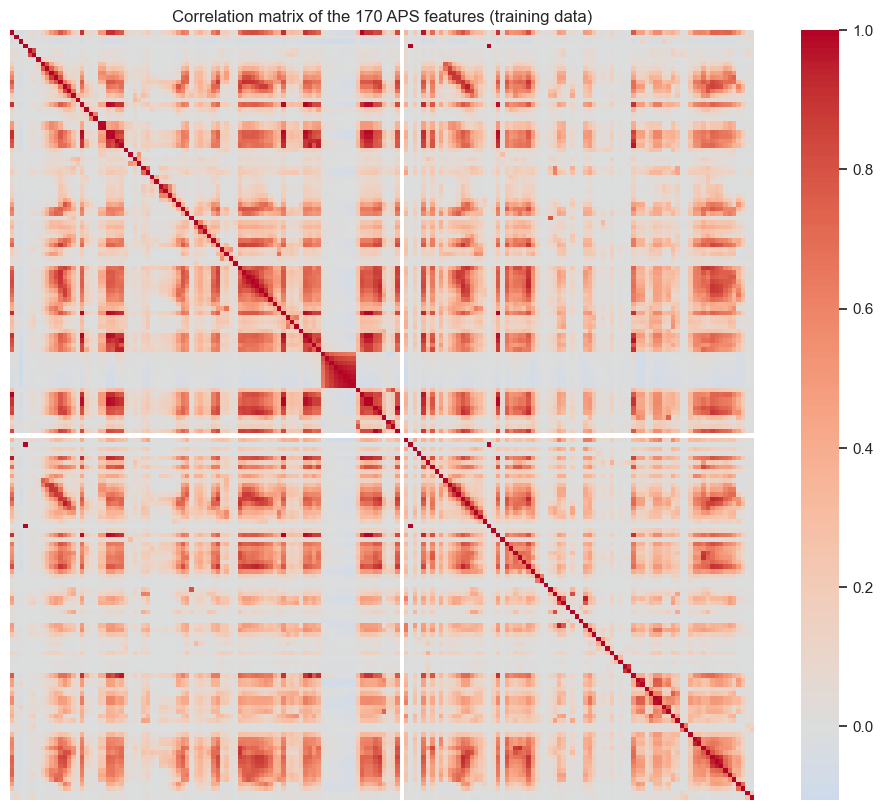

In [6]:
plt.figure(figsize=(12, 10))
sns.heatmap(X_train.corr(), cmap="coolwarm", center=0, xticklabels=False, yticklabels=False)
plt.title("Correlation matrix of the 170 APS features (training data)")
plt.show()

Most correlations are positive, and there are large blocks of strongly correlated features (dark red). Many APS features are histogram bins of the same underlying sensor reading (e.g., `ag_000`–`ag_009`), and counts that scale with how much a truck is used rise together. The white row and column belong to a constant feature, whose correlation is undefined. This redundancy suggests that many features carry overlapping information.

### 1(b)iv Scatter plots and box plots of the ⌊√170⌋ = 13 highest-CV features

To keep the pair plot readable, it uses all 1,000 positives and a random sample of 3,000 negatives. The box plots use all training data on a symmetric-log scale, because the features are extremely skewed.

13 ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


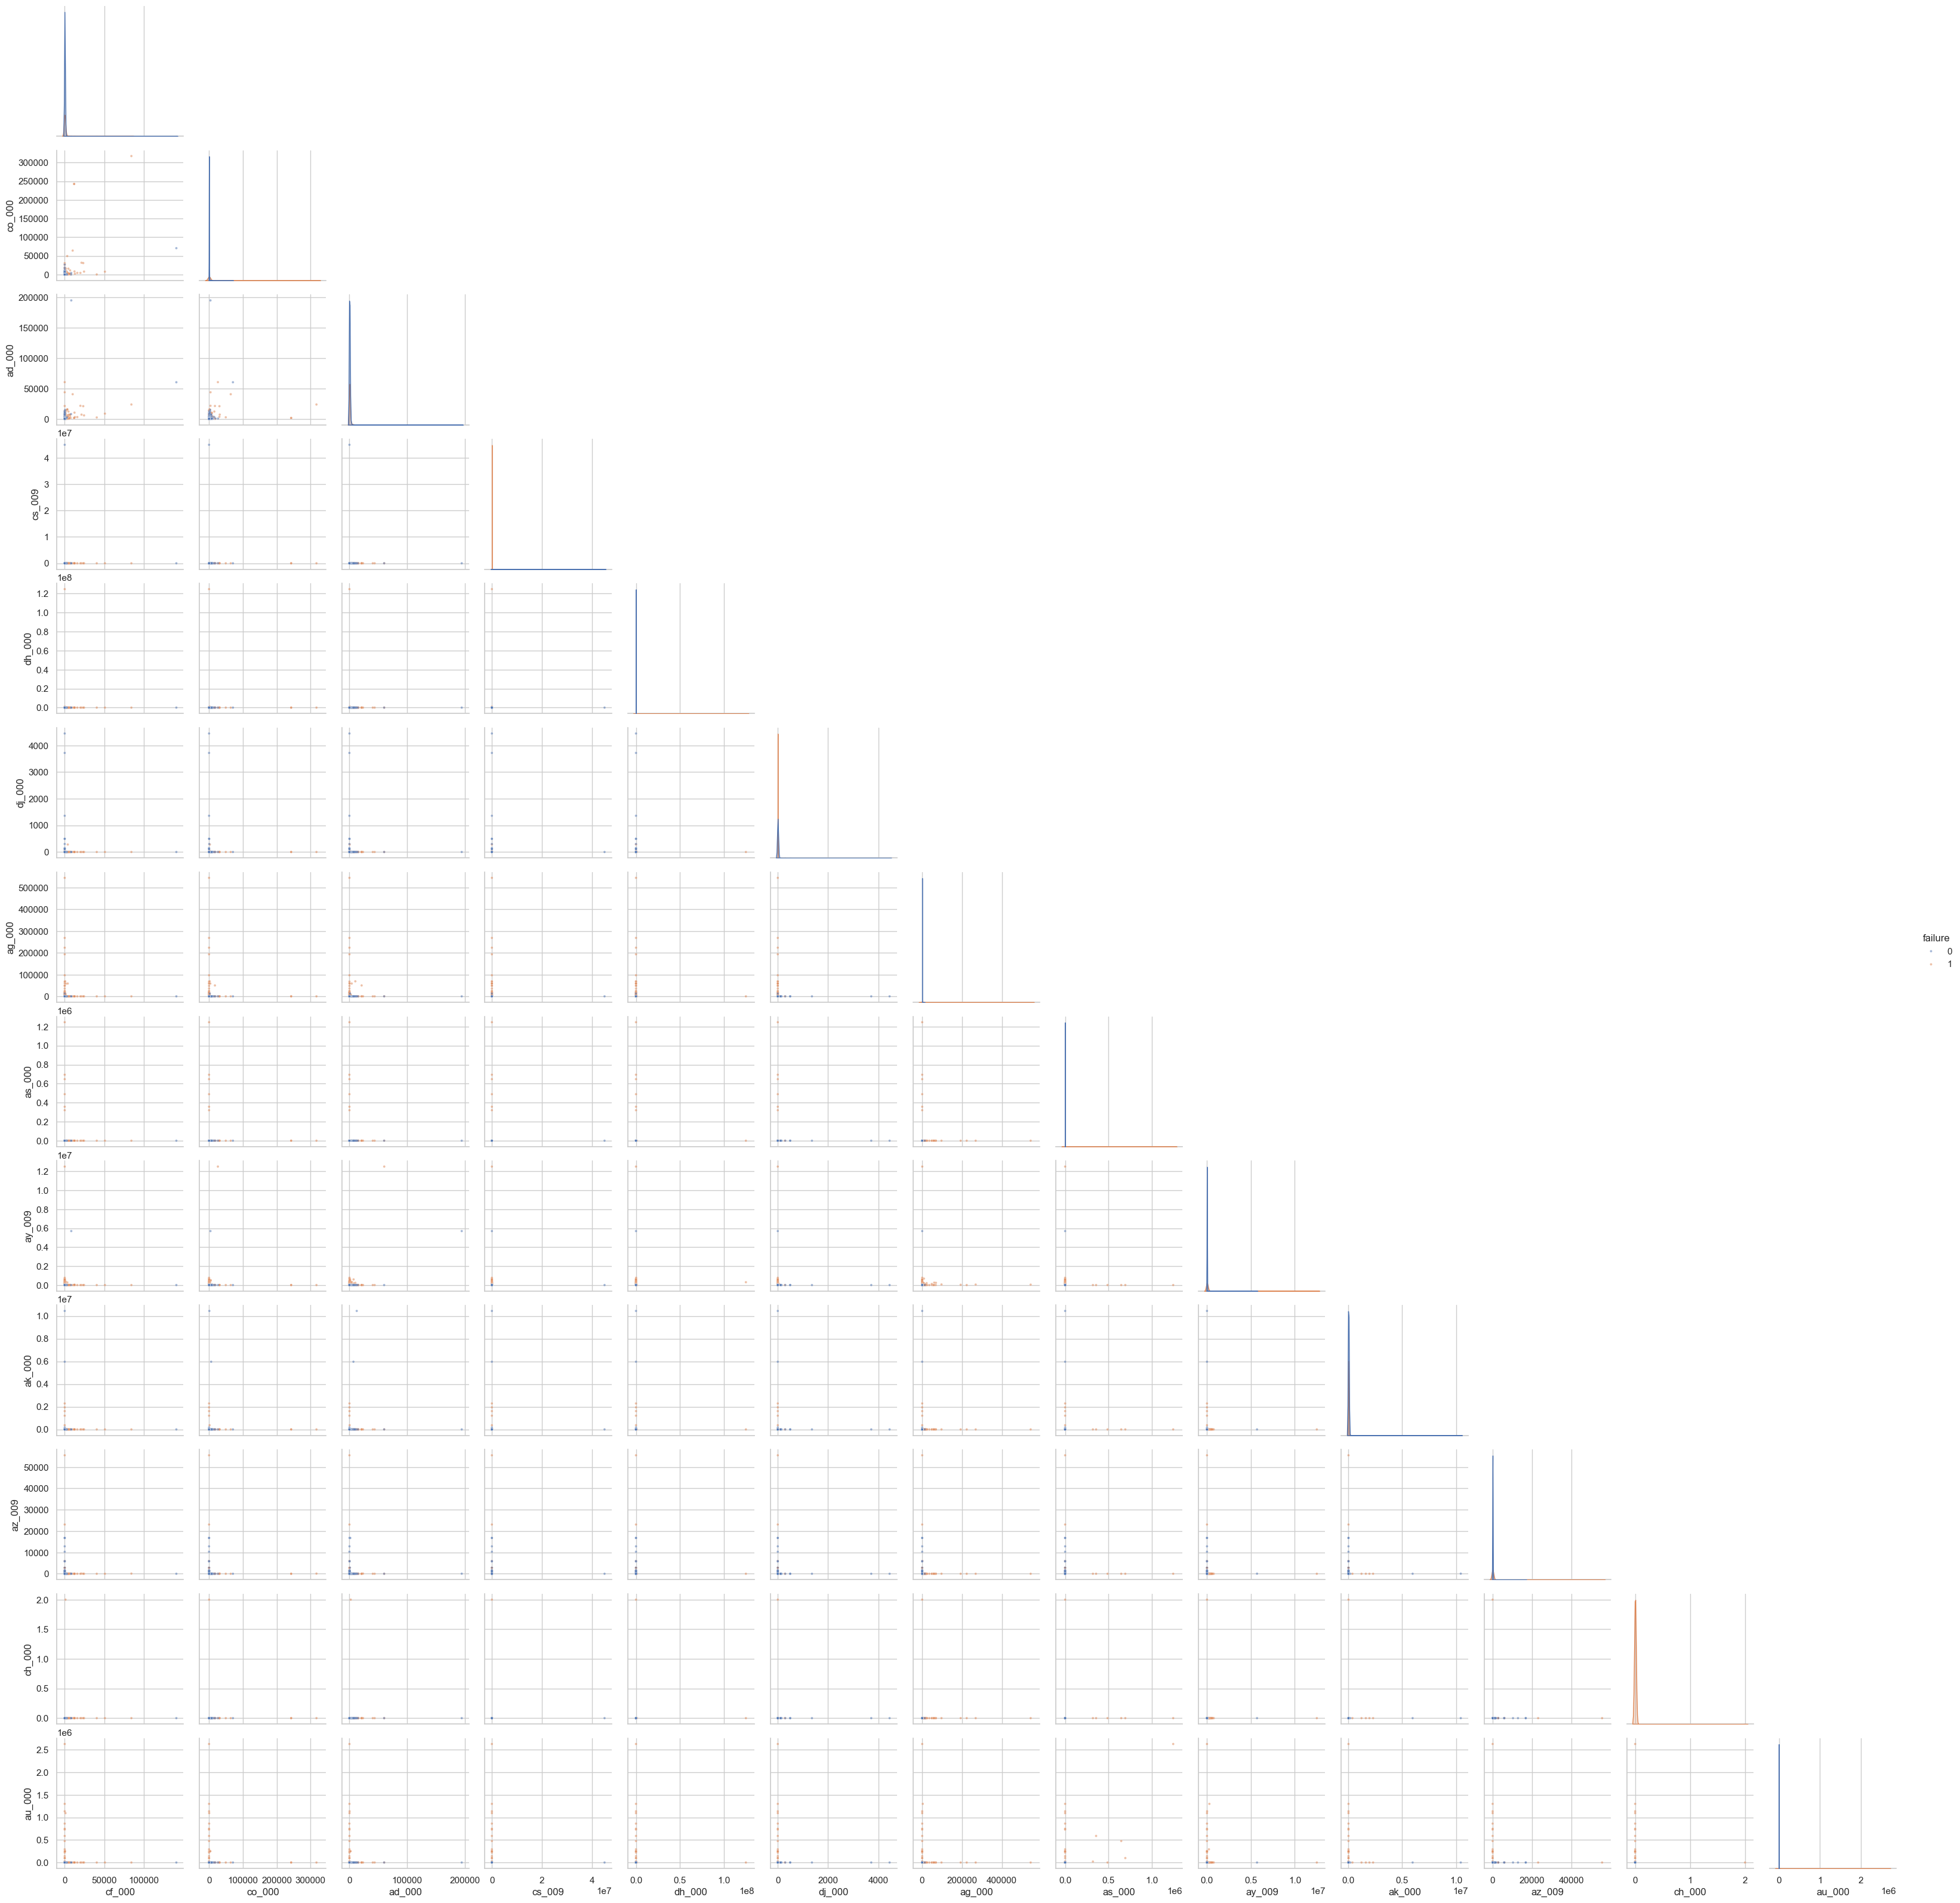

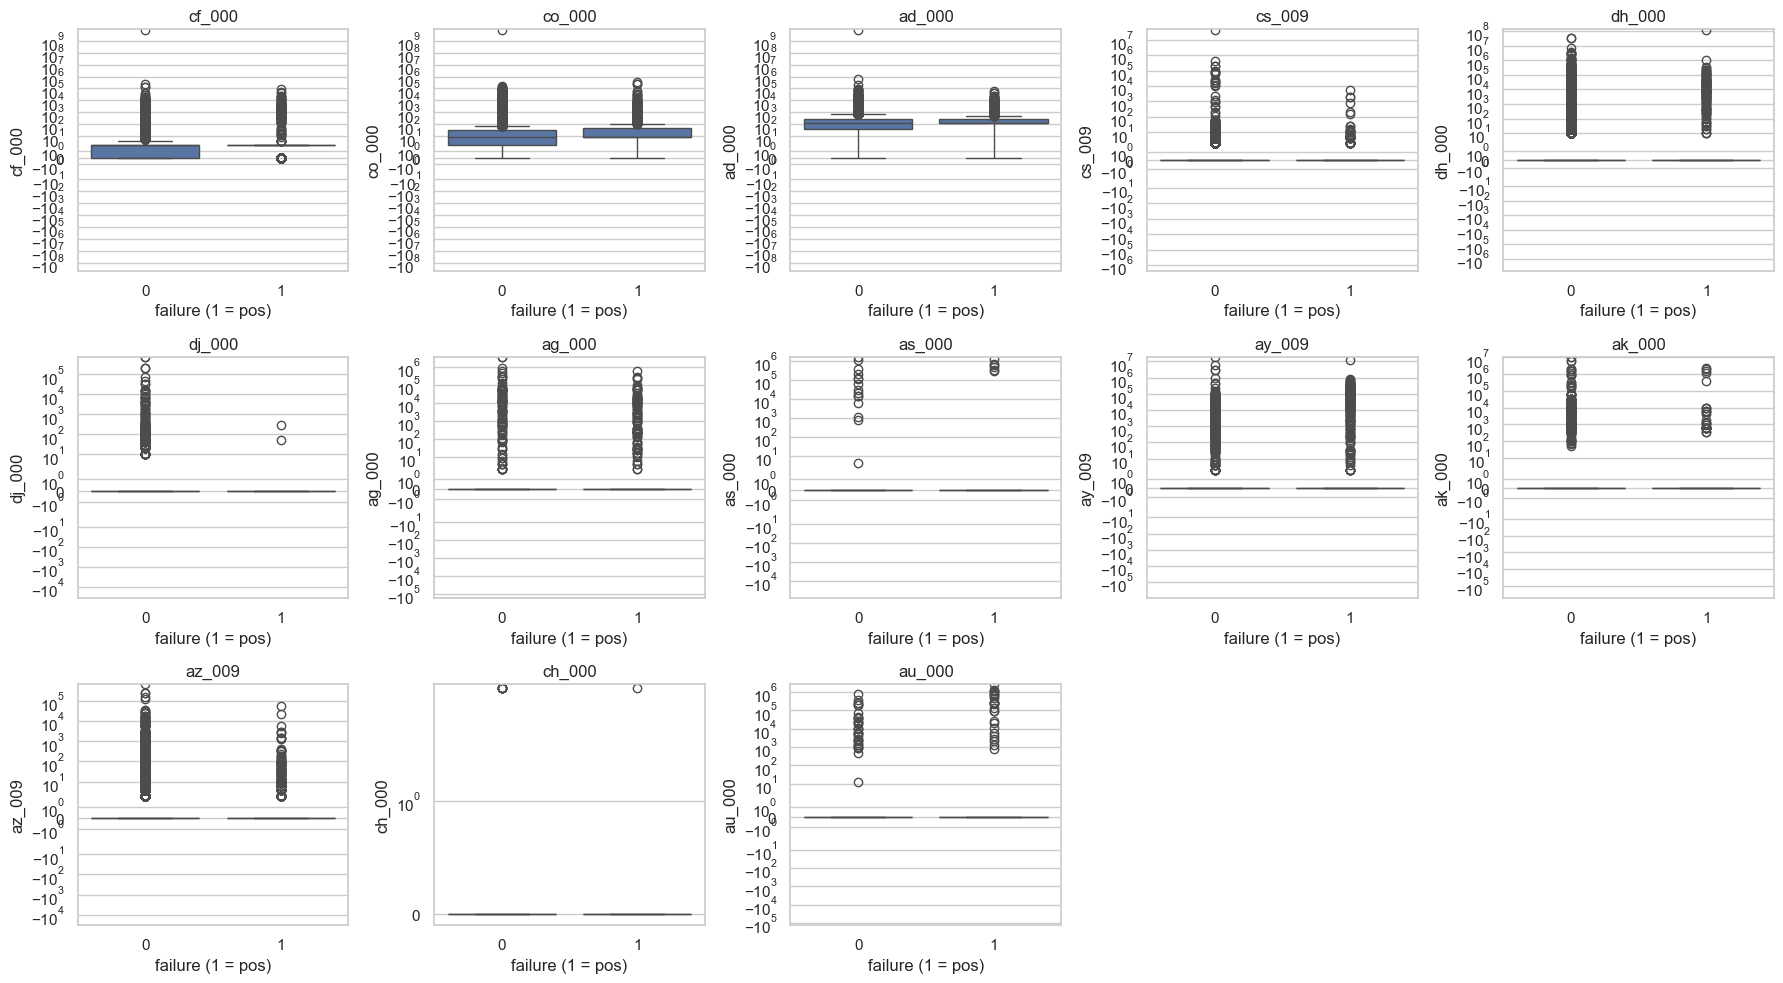

In [7]:
k = int(np.sqrt(170))
top = list(cv_feat.index[:k])
print(k, top)

idx = pd.concat([y_train[y_train == 1], y_train[y_train == 0].sample(3000, random_state=0)]).index
sample = X_train.loc[idx, top].assign(failure=y_train.loc[idx])

sns.pairplot(sample, vars=top, hue="failure", corner=True, plot_kws={"s": 8, "alpha": 0.5})
plt.show()

fig, axes = plt.subplots(3, 5, figsize=(18, 10))
for ax, f in zip(axes.flat, top):
    sns.boxplot(x=y_train, y=X_train[f], ax=ax)
    ax.set_yscale("symlog")
    ax.set_xlabel("failure (1 = pos)")
    ax.set_title(f)
for ax in axes.flat[k:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Can we draw conclusions about significance from the scatter plots alone?** No. The scatter plots show only two features at a time, and the positives overlap heavily with the negatives in nearly every panel. Significance depends on a feature's contribution *given all the other features* and requires a model and a formal test; with many correlated features, a feature that looks related on its own may add nothing once the others are included. The box plots are suggestive at most: for a few features (e.g., `cf_000`, `co_000`, `ad_000`) the positives sit somewhat higher, but for most of them both classes have a median of 0 and differ only in their outliers. High CV also measures spread, not predictive importance.

### 1(b)v Class balance

In [8]:
print(y_train.value_counts())
print("Positive fraction:", y_train.mean().round(4))

class
0    59000
1     1000
Name: count, dtype: int64
Positive fraction: 0.0167


The training set has **59,000 negatives and 1,000 positives** (1.67% positive), so the data set is **severely imbalanced**. A classifier that always predicts "negative" would already reach 98.3% accuracy, so misclassification alone is a poor measure of performance here. The confusion matrices below are written as `[[TN, FP], [FN, TP]]`; the key number is **FN**, the real failures a model misses.

### Evaluation helper

Prints the confusion matrix, misclassification rate, and AUC for the training and test sets, plots both ROC curves, and stores the results for the final table.

In [9]:
summary = {}

def evaluate(model, name):
    fig, ax = plt.subplots(figsize=(6, 5))
    out = {}
    for split, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
        pred = model.predict(X)
        prob = model.predict_proba(X)[:, 1]
        err, auc = 1 - accuracy_score(y, pred), roc_auc_score(y, prob)
        print(f"--- {name}: {split} ---")
        print(confusion_matrix(y, pred))
        print(f"Misclassification: {err:.4f}   AUC: {auc:.4f}\n")
        RocCurveDisplay.from_predictions(y, prob, name=f"{split} (AUC={auc:.3f})", ax=ax)
        out[f"{split}_err"], out[f"{split}_auc"] = err, auc
    ax.set_title(f"ROC: {name}")
    plt.show()
    summary[name] = out

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

### 1(c) Random forest without class-imbalance compensation

--- RF (uncompensated): train ---
[[59000     0]
 [    0  1000]]
Misclassification: 0.0000   AUC: 1.0000

--- RF (uncompensated): test ---
[[15609    16]
 [  102   273]]
Misclassification: 0.0074   AUC: 0.9944



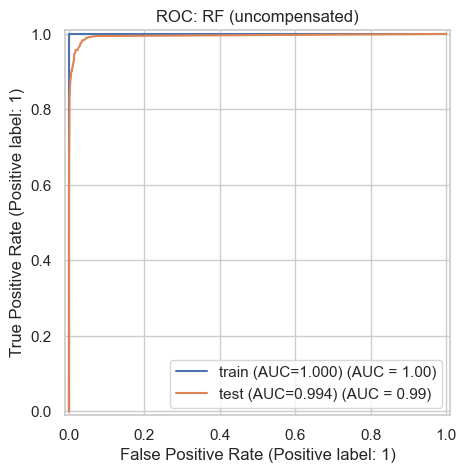

OOB error estimate: 0.0057


In [10]:
rf = RandomForestClassifier(n_estimators=200, oob_score=True, n_jobs=-1, random_state=0)
rf.fit(X_train, y_train)

evaluate(rf, "RF (uncompensated)")
print("OOB error estimate:", round(1 - rf.oob_score_, 4))
summary["RF (uncompensated)"]["oob_err"] = 1 - rf.oob_score_

- **Training set:** perfect (misclassification 0, AUC 1.0). Random-forest trees are grown deep and essentially memorize the training data, so training error is not informative.
- **Test set:** misclassification 0.0074 and AUC 0.994. However, the model **misses 102 of the 375 failures (27%)**, while raising only 16 false alarms. The low error rate mostly reflects the many easy negatives.
- **Out-of-bag error:** 0.0057, close to the test error of 0.0074. Each tree is evaluated on the roughly 37% of training rows left out of its bootstrap sample, so the OOB error is an honest estimate that requires no separate validation set. It is slightly lower than the test error, partly because the test set has a higher share of positives (2.3% vs. 1.7%), which are the hard cases.

### 1(d) Random forest with class-imbalance compensation

**How class imbalance is addressed in random forests:**
- **Class weighting (cost-sensitive learning):** errors on the minority class are weighted more heavily when choosing splits and when voting.
- **Balanced random forest:** each tree is grown on a bootstrap sample in which the majority class is undersampled to the size of the minority class.
- **Oversampling** the minority class, e.g., with SMOTE (used in 1(f)).
- **Threshold moving:** classify as positive when the predicted probability exceeds a cutoff lower than 0.5.

I used class weighting with `class_weight="balanced_subsample"`, which weights each class inversely to its frequency within each tree's bootstrap sample (each positive counts about 59 times as much as a negative).

--- RF (class-weighted): train ---
[[59000     0]
 [    0  1000]]
Misclassification: 0.0000   AUC: 1.0000

--- RF (class-weighted): test ---
[[15609    16]
 [  164   211]]
Misclassification: 0.0112   AUC: 0.9933



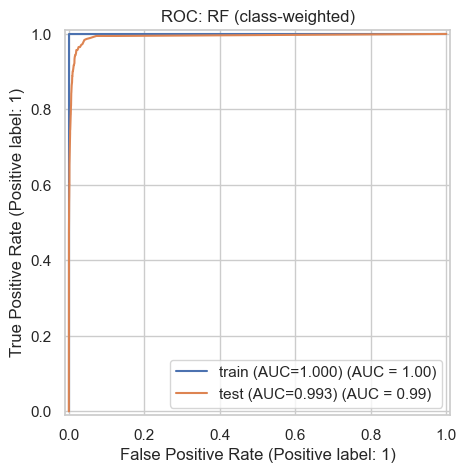

OOB error estimate: 0.0076


In [11]:
rf_bal = RandomForestClassifier(n_estimators=200, oob_score=True, n_jobs=-1,
                                random_state=0, class_weight="balanced_subsample")
rf_bal.fit(X_train, y_train)

evaluate(rf_bal, "RF (class-weighted)")
print("OOB error estimate:", round(1 - rf_bal.oob_score_, 4))
summary["RF (class-weighted)"]["oob_err"] = 1 - rf_bal.oob_score_

**Comparison with 1(c):** compare the test confusion matrices, AUC, and OOB error of the two forests. Class weighting changes the forest only modestly here: because the trees are grown until their leaves are pure, most leaves contain a single class, and reweighting has little effect on their votes. Weighting mainly helps when the trees are restricted (e.g., by `min_samples_leaf`), when the forest is undersampled per tree (balanced random forest), or when it is combined with a lower decision threshold. Methods that change the training data itself, such as SMOTE in 1(f), have a larger effect on the number of missed failures.

### 1(e) XGBoost with an L1 penalty, without compensation

XGBoost fits an additive model of trees whose outputs are combined through a **logistic** link (`objective="binary:logistic"`), and `reg_alpha` adds an **L1 penalty** on the leaf weights. This is how XGBoost approximates the L1-penalized logistic model tree described in the assignment; strictly speaking, its trees still use univariate splits, with the logistic model and L1 penalty applied to the combined tree outputs. α is chosen by stratified 5-fold cross-validation, which also provides the cross-validation error estimate.

Best alpha: 1
5-fold CV error: 0.0057
--- XGBoost L1 (uncompensated): train ---
[[58996     4]
 [   54   946]]
Misclassification: 0.0010   AUC: 0.9996

--- XGBoost L1 (uncompensated): test ---
[[15605    20]
 [   89   286]]
Misclassification: 0.0068   AUC: 0.9957



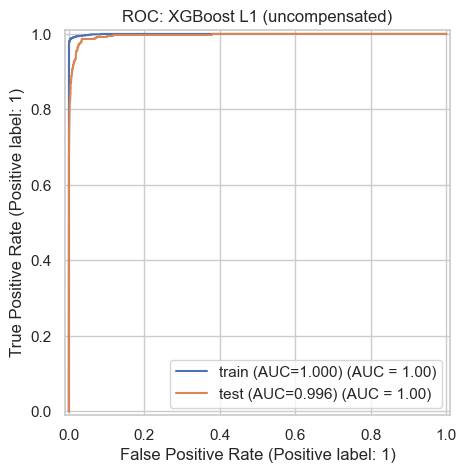

In [12]:
xgb_base = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4,
                         tree_method="hist", n_jobs=-1, eval_metric="logloss", random_state=0)

xgb_grid = GridSearchCV(xgb_base, {"reg_alpha": [0, 0.1, 1, 10]},
                        cv=skf, scoring="accuracy")
xgb_grid.fit(X_train, y_train)

print("Best alpha:", xgb_grid.best_params_["reg_alpha"])
print("5-fold CV error:", round(1 - xgb_grid.best_score_, 4))
evaluate(xgb_grid.best_estimator_, "XGBoost L1 (uncompensated)")
summary["XGBoost L1 (uncompensated)"]["cv_err"] = 1 - xgb_grid.best_score_

- **Best α = 1.** The **5-fold CV error is 0.0057**, close to the **test error of 0.0068**; the small gap again reflects the higher share of positives in the test set.
- **Training:** misclassification 0.0010, AUC 0.9996. Unlike the random forest, the boosted model does not memorize the training data.
- **Test:** misclassification 0.0068, AUC 0.996, the best of the uncompensated models. It still **misses 89 of the 375 failures (24%)**, with 20 false alarms.

### 1(f) SMOTE + XGBoost

SMOTE creates synthetic positives by interpolating between each real positive and its nearest positive neighbors until the classes are balanced.

**Right vs. wrong way to cross-validate.** The *wrong* way is to apply SMOTE to the whole training set and then cross-validate: the synthetic positives are built from real positives, so the validation folds contain near-copies of points the model trained on, and the CV error is optimistically biased. The *right* way, used here, puts SMOTE inside an `imblearn` pipeline, so in each fold SMOTE is applied **only to that fold's training portion**, and the model is scored on the untouched validation portion with its real class balance. The final model is refit with SMOTE on the full training set and evaluated on the original (non-oversampled) training and test sets.

Best alpha: 0.1
5-fold CV error: 0.0091
--- XGBoost L1 + SMOTE: train ---
[[58767   233]
 [   56   944]]
Misclassification: 0.0048   AUC: 0.9988

--- XGBoost L1 + SMOTE: test ---
[[15460   165]
 [   46   329]]
Misclassification: 0.0132   AUC: 0.9942



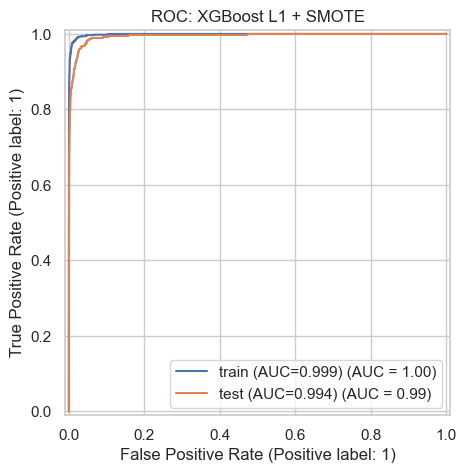

In [13]:
smote_pipe = ImbPipeline([
    ("smote", SMOTE(random_state=0)),
    ("xgb", XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4,
                          tree_method="hist", n_jobs=-1, eval_metric="logloss", random_state=0)),
])

smote_grid = GridSearchCV(smote_pipe, {"xgb__reg_alpha": [0, 0.1, 1, 10]},
                          cv=skf, scoring="accuracy")
smote_grid.fit(X_train, y_train)

print("Best alpha:", smote_grid.best_params_["xgb__reg_alpha"])
print("5-fold CV error:", round(1 - smote_grid.best_score_, 4))
evaluate(smote_grid.best_estimator_, "XGBoost L1 + SMOTE")
summary["XGBoost L1 + SMOTE"]["cv_err"] = 1 - smote_grid.best_score_

**Comparison of the uncompensated and SMOTE models (test set):**

| | Missed failures (FN) | False alarms (FP) | Misclassification | AUC |
|---|---|---|---|---|
| XGBoost L1, uncompensated | 89 of 375 (24%) | 20 | 0.0068 | 0.996 |
| XGBoost L1 + SMOTE | **46 of 375 (12%)** | 165 | 0.0132 | 0.994 |

SMOTE **halves the number of missed failures** (89 → 46) at the cost of more false alarms (20 → 165), so the overall misclassification rate roughly doubles while the AUC stays nearly the same. Training on balanced data shifts the model's predicted probabilities toward the positive class, so at the default 0.5 threshold it flags more trucks. Which model is better depends on the cost of each error. In the APS setting, a missed failure (a breakdown on the road) is far more expensive than an unnecessary inspection; the data set's documentation assigns a cost of 500 to a missed failure and 10 to a false alarm, giving a total test cost of 89·500 + 20·10 = 44,700 for the uncompensated model and 46·500 + 165·10 = 24,650 with SMOTE. By that measure SMOTE is clearly better, even though its misclassification rate is higher.

The SMOTE model's CV error (0.0091) is lower than its test error (0.0132), mainly because the test set has a higher share of positives and the SMOTE model's errors are concentrated in the false alarms it produces on the large negative class.

### Summary of all models

In [14]:
pd.DataFrame(summary).T.round(4)

,train_err,train_auc,test_err,test_auc,oob_err,cv_err
RF (uncompensated),0.0000,1.0000,0.0074,0.9944,0.0057,NaN
RF (class-weighted),0.0000,1.0000,0.0112,0.9933,0.0076,NaN
XGBoost L1 (uncompensated),0.0010,0.9996,0.0068,0.9957,NaN,0.0057
XGBoost L1 + SMOTE,0.0048,0.9988,0.0132,0.9942,NaN,0.0091


## 2. ISLR 6.6.3

The lasso is fit by minimizing the RSS subject to $\sum_j |\beta_j| \le s$. At $s = 0$ every $\beta_j = 0$ and the model only predicts the mean; as $s$ grows the constraint loosens, and once $s \ge \sum_j|\hat\beta_j^{\text{OLS}}|$ the solution is ordinary least squares. **Increasing $s$ therefore increases flexibility.**

**(a) Training RSS: iv. Steadily decrease.** The set of allowed coefficients only grows with $s$, so the minimal training RSS can never increase. It decreases until $s$ reaches the least-squares solution and then stays constant.

**(b) Test RSS: ii. Decrease initially, then increase in a U shape.** At first, letting useful predictors in reduces bias faster than variance grows; for large $s$ the model starts fitting noise and test RSS rises again.

**(c) Variance: iii. Steadily increase.** At $s = 0$ the model is a constant with essentially no variance; as $s$ grows the coefficients depend more on the particular training sample.

**(d) Squared bias: iv. Steadily decrease.** A more flexible model can approximate the true relationship more closely.

**(e) Irreducible error: v. Remain constant.** It is the variance of the noise $\varepsilon$, a property of the data that does not depend on the model.

## 3. ISLR 6.6.5

Because $x_{11} = x_{12}$ and $x_{21} = x_{22}$, the two predictors are identical, and the fit depends only on $\beta_1 + \beta_2$.

**(a)** Ridge regression:
$$\min_{\beta_1,\beta_2}\ \big(y_1 - (\beta_1+\beta_2)x_{11}\big)^2 + \big(y_2 - (\beta_1+\beta_2)x_{21}\big)^2 + \lambda(\beta_1^2 + \beta_2^2).$$

**(b)** Setting the partial derivatives to zero gives two equations whose RSS terms are identical, because the RSS depends only on $\beta_1 + \beta_2$:
$$-2x_{11}\big(y_1 - (\beta_1+\beta_2)x_{11}\big) - 2x_{21}\big(y_2 - (\beta_1+\beta_2)x_{21}\big) + 2\lambda\beta_j = 0, \quad j = 1, 2.$$
Subtracting them gives $2\lambda(\beta_1 - \beta_2) = 0$, so $\hat\beta_1 = \hat\beta_2$ for $\lambda > 0$. Equivalently, for a fixed sum $c = \beta_1 + \beta_2$, the penalty $\beta_1^2 + \beta_2^2 = c^2/2 + (\beta_1 - \beta_2)^2/2$ is minimized when $\beta_1 = \beta_2$.

**(c)** Lasso:
$$\min_{\beta_1,\beta_2}\ \big(y_1 - (\beta_1+\beta_2)x_{11}\big)^2 + \big(y_2 - (\beta_1+\beta_2)x_{21}\big)^2 + \lambda(|\beta_1| + |\beta_2|).$$

**(d)** The RSS depends only on $c = \beta_1 + \beta_2$, and by the triangle inequality $|\beta_1| + |\beta_2| \ge |c|$, with equality whenever $\beta_1$ and $\beta_2$ have the same sign (or one is 0). So if $c^*$ is the optimal sum, **every** pair with $\beta_1 + \beta_2 = c^*$ and $\beta_1, \beta_2$ of the same sign as $c^*$ has the same RSS and the same penalty, and all of them are solutions: the line segment from $(c^*, 0)$ to $(0, c^*)$. Geometrically, the RSS contours are lines $\beta_1 + \beta_2 = \text{const}$, parallel to an edge of the lasso diamond $|\beta_1| + |\beta_2| \le s$, so the optimal contour touches a whole edge rather than a single corner.

## 4. ISLR 8.4.5

**Majority vote → Red.** Six of the ten estimates (0.55, 0.6, 0.6, 0.65, 0.7, 0.75) exceed 0.5, so there are 6 votes for Red and 4 for Green.

**Average probability → Green.** The mean estimate is $4.5 / 10 = 0.45 < 0.5$.

The approaches disagree because majority vote ignores confidence: the six Red votes are only slightly above 0.5, while the four Green votes are very confident (P(Red) of 0.1–0.2).

## 5. ISLR 9.7.3

**(a)** Red: (3, 4), (2, 2), (4, 4), (1, 4); Blue: (2, 1), (4, 3), (4, 1). All Red points lie on or above the line $X_2 = X_1$ and all Blue points lie below it, so the classes are separable (plot below).

**(b)** The closest pairs across classes are Red (2, 2) and Blue (2, 1), and Red (4, 4) and Blue (4, 3). The Red pair lies on $X_2 = X_1$ and the Blue pair on $X_2 = X_1 - 1$, so the maximal margin hyperplane lies halfway between: $X_2 = X_1 - 0.5$, i.e. $\;0.5 - X_1 + X_2 = 0$.

**(c)** Classify to **Red if $0.5 - X_1 + X_2 > 0$**, and to Blue otherwise: $\beta_0 = 0.5$, $\beta_1 = -1$, $\beta_2 = 1$.

**(d)** The margin edges are $X_2 = X_1$ and $X_2 = X_1 - 1$. The margin is $M = 0.5/\sqrt{2} \approx 0.354$.

**(e)** The support vectors are Red (2, 2) and (4, 4), and Blue (2, 1) and (4, 3).

**(f)** Observation 7, at (4, 1), is not a support vector: its distance to the hyperplane is $2.5/\sqrt2 \approx 1.77$, far outside the margin. The maximal margin hyperplane depends only on the support vectors, so a small movement of observation 7 that keeps it outside the margin does not change the hyperplane.

**(g)** For example, $0.2 - X_1 + X_2 = 0$ separates the classes but is closer to the Red support vectors, with a margin of only $0.2/\sqrt2 \approx 0.14$.

**(h)** Adding a Red point at (4, 2) makes the classes non-separable: it lies between Blue (4, 1) and Blue (4, 3) on the line $X_1 = 4$, so any line placing it on the Red side also places one of those Blue points there.

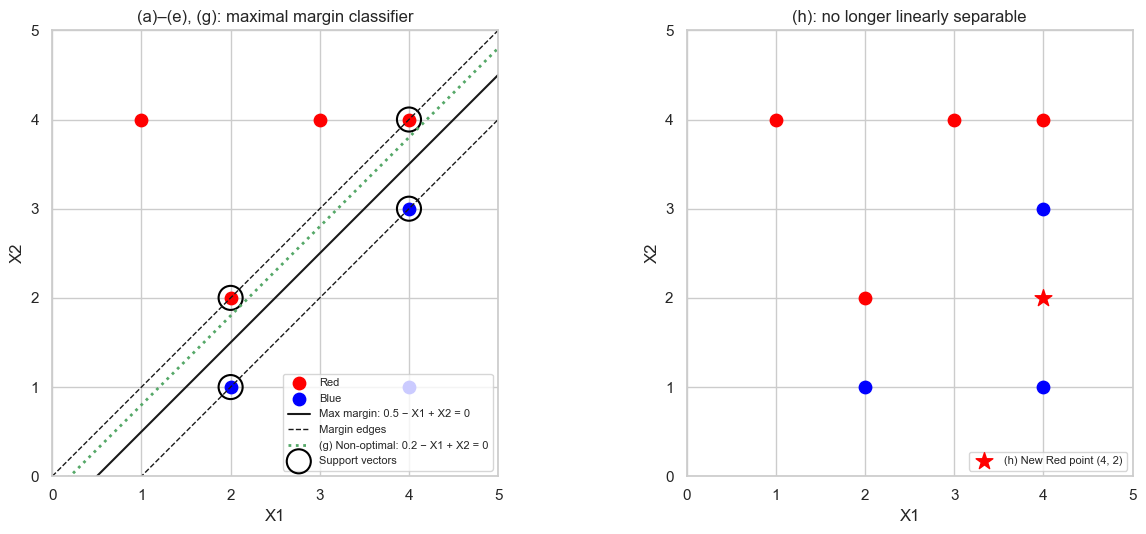

In [15]:
red  = np.array([[3, 4], [2, 2], [4, 4], [1, 4]])
blue = np.array([[2, 1], [4, 3], [4, 1]])
x = np.linspace(0, 5, 100)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

ax = axes[0]
ax.scatter(*red.T, c="red", s=80, label="Red")
ax.scatter(*blue.T, c="blue", s=80, label="Blue")
ax.plot(x, x - 0.5, "k-", label="Max margin: 0.5 − X1 + X2 = 0")
ax.plot(x, x, "k--", lw=1, label="Margin edges")
ax.plot(x, x - 1, "k--", lw=1)
ax.plot(x, x - 0.2, "g:", lw=2, label="(g) Non-optimal: 0.2 − X1 + X2 = 0")
sv = np.array([[2, 2], [4, 4], [2, 1], [4, 3]])
ax.scatter(*sv.T, s=300, facecolors="none", edgecolors="black", lw=1.5, label="Support vectors")
ax.set_title("(a)–(e), (g): maximal margin classifier")

ax = axes[1]
ax.scatter(*red.T, c="red", s=80)
ax.scatter(*blue.T, c="blue", s=80)
ax.scatter(4, 2, c="red", s=160, marker="*", label="(h) New Red point (4, 2)")
ax.set_title("(h): no longer linearly separable")

for ax in axes:
    ax.set_xlim(0, 5); ax.set_ylim(0, 5); ax.set_aspect("equal")
    ax.set_xlabel("X1"); ax.set_ylabel("X2"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## 6. Extra practice (not required)

### ISLR 9.7.2

**(a)–(b)** $(1+X_1)^2 + (2-X_2)^2 = 4$ is a circle centered at $(-1, 2)$ with radius 2. Points with value $> 4$ lie outside the circle; points with value $\le 4$ lie inside or on it.

**(c)** (0, 0): $1 + 4 = 5 > 4$ → **Blue**. (−1, 1): $0 + 1 = 1$ → **Red**. (2, 2): $9 + 0 = 9$ → **Blue**. (3, 8): $16 + 36 = 52$ → **Blue**.

**(d)** Expanding gives $1 + 2X_1 + X_1^2 - 4X_2 + X_2^2 = 0$, which is linear in the features $X_1, X_1^2, X_2, X_2^2$ with coefficients $(\beta_0, \beta_1, \beta_2, \beta_3, \beta_4) = (1, 2, 1, -4, 1)$. The boundary is a circle in the original space but a hyperplane in the expanded feature space.

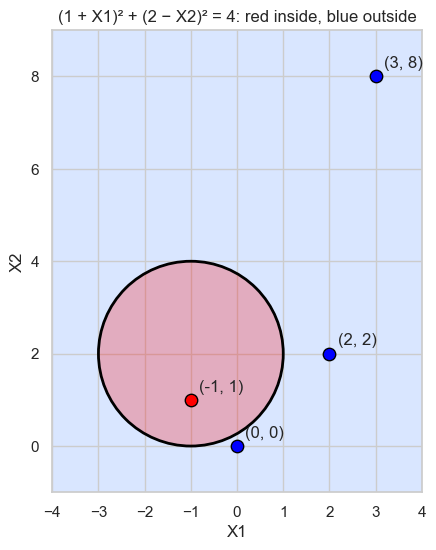

In [16]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_facecolor((0.85, 0.9, 1.0))   # outside the circle: Blue
ax.add_patch(plt.Circle((-1, 2), 2, color="red", alpha=0.25))
ax.add_patch(plt.Circle((-1, 2), 2, fill=False, color="black", lw=2))
for (a, b) in [(0, 0), (-1, 1), (2, 2), (3, 8)]:
    color = "blue" if (1 + a)**2 + (2 - b)**2 > 4 else "red"
    ax.scatter(a, b, c=color, s=80, edgecolors="black")
    ax.annotate(f"({a}, {b})", (a, b), textcoords="offset points", xytext=(6, 6))
ax.set_xlim(-4, 4); ax.set_ylim(-1, 9); ax.set_aspect("equal")
ax.set_xlabel("X1"); ax.set_ylabel("X2")
ax.set_title("(1 + X1)² + (2 − X2)² = 4: red inside, blue outside")
plt.show()

### ISLR 8.4.4

*Based on the standard version of ISLR Figure 8.14.*

**(a)** Tree for the left-hand partition:

```
X1 < 1?
├── yes: X2 < 1?
│   ├── yes: X1 < 0?
│   │   ├── yes: 3
│   │   └── no:  X2 < 0?
│   │       ├── yes: 10
│   │       └── no:  0
│   └── no:  15
└── no:  5
```

**(b)** Partition for the right-hand tree (region means): $X_2 < 1, X_1 < 1$: −1.80; $X_2 < 1, X_1 \ge 1$: 0.63; $1 \le X_2 < 2, X_1 < 0$: −1.06; $1 \le X_2 < 2, X_1 \ge 0$: 0.21; $X_2 \ge 2$: 2.49.

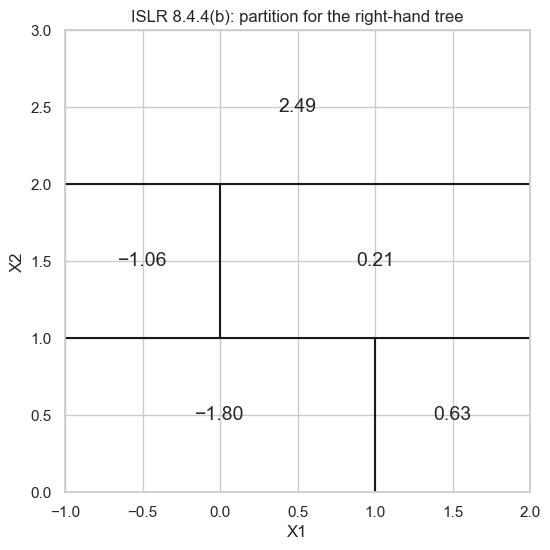

In [17]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-1, 2); ax.set_ylim(0, 3)
ax.axhline(1, color="k"); ax.plot([1, 1], [0, 1], "k")
ax.axhline(2, color="k"); ax.plot([0, 0], [1, 2], "k")
for (x, y, m) in [(0, 0.5, "−1.80"), (1.5, 0.5, "0.63"),
                  (-0.5, 1.5, "−1.06"), (1, 1.5, "0.21"), (0.5, 2.5, "2.49")]:
    ax.text(x, y, m, ha="center", va="center", fontsize=14)
ax.set_xlabel("X1"); ax.set_ylabel("X2")
ax.set_title("ISLR 8.4.4(b): partition for the right-hand tree")
plt.show()